# Lab 12: Numerical Integration

**Numerical integration** (quadrature) approximates the definite integral
$$I = \int_a^b f(x)\,dx$$
when an analytical antiderivative is unavailable, expensive, or the function is known only at discrete points.

## Learning Objectives

By the end of this session, you will be able to:
- Apply the **Trapezoidal** and **Simpson's** rules (single-segment and composite)
- Understand and estimate **truncation error** for Newton-Cotes formulas
- Use **Richardson extrapolation** and **Romberg integration** for higher accuracy
- Derive and implement **Gauss-Legendre quadrature** nodes and weights
- Implement **Gauss-Lobatto quadrature** and explain when to prefer it
- Use `scipy.integrate.quad` / `fixed_quad` for practical engineering problems
- Select the appropriate integration method for a given problem

## Session Outline

| # | Topic |
|---|-------|
| 1 | Introduction & benchmark function |
| 2 | Trapezoidal Rule |
| 3 | Simpson's Rules |
| 4 | Richardson Extrapolation & Romberg Integration |
| 5 | Gauss-Legendre Quadrature |
| 6 | Gauss-Lobatto Quadrature |
| 7 | `scipy.integrate` |
| 8 | Engineering Applications |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from numpy.polynomial.legendre import leggauss

---
## 1. Introduction: Benchmark Function

Throughout this lab we use a single **benchmark function** whose exact integral is known:

$$f(x) = 0.2 + 25x - 200x^2 + 675x^3 - 900x^4 + 400x^5, \quad x \in [0,\, 0.8]$$

$$I_{\text{exact}} = \int_0^{0.8} f(x)\,dx = 1.640533\ldots$$

We define **percent true relative error** as
$$\varepsilon_t = \left|\frac{I_{\text{exact}} - I_{\text{approx}}}{I_{\text{exact}}}\right| \times 100\,\%$$

All methods will be compared against this benchmark.

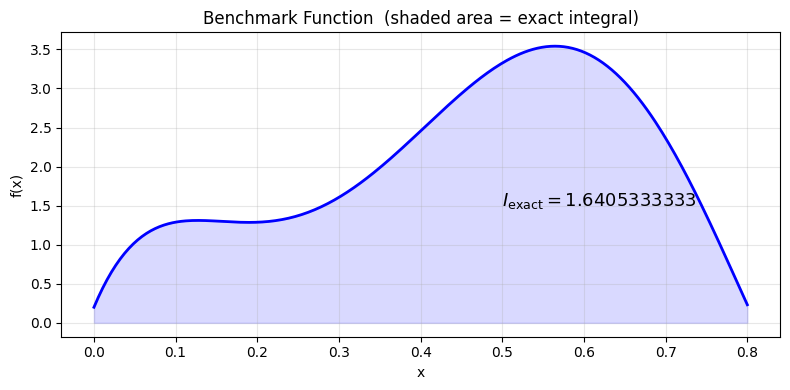

In [2]:
# Benchmark function and exact integral
f   = lambda x: 0.2 + 25*x - 200*x**2 + 675*x**3 - 900*x**4 + 400*x**5
a, b  = 0.0, 0.8
# Exact integral, computed in closed form:
#   F(x) = 0.2x + 12.5 x^2 - (200/3) x^3 + (675/4) x^4 - 180 x^5 + (200/3) x^6
#   F(0.8) - F(0) = 49216/30000 = 3076/1875 = 1.6405333333...
I_exact = 49216 / 30000     # = 1.6405333333... (full double precision)

def pct_err(I_approx):
    """Percent true relative error."""
    return abs(I_exact - I_approx) / abs(I_exact) * 100

# Visualise
x_plot = np.linspace(a, b, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_plot, f(x_plot), 'b-', lw=2)
ax.fill_between(x_plot, f(x_plot), alpha=0.15, color='blue')
ax.set(xlabel='x', ylabel='f(x)', title='Benchmark Function  (shaded area = exact integral)')
ax.text(0.5, 1.5, f'$I_{{\\rm exact}} = {I_exact:.10f}$', fontsize=13)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


---
## 2. Trapezoidal Rule

### 2.1 Single-Segment Formula

Approximate $f$ by a **linear** polynomial through $(a, f(a))$ and $(b, f(b))$:

$$I \approx (b-a)\,\frac{f(a)+f(b)}{2}$$

**Truncation error** (exact for polynomials of degree $\leq 1$):
$$E_t = -\frac{1}{12}f''(\xi)(b-a)^3, \quad \xi \in [a,b]$$

### 2.2 Composite Trapezoidal Rule

Divide $[a,b]$ into $n$ equal sub-intervals of width $h = (b-a)/n$:

$$I \approx \frac{h}{2}\left[f(x_0) + 2\sum_{i=1}^{n-1}f(x_i) + f(x_n)\right]$$

**Global error** $\propto h^2 \propto n^{-2}$: doubling $n$ reduces error by $\approx 4\times$.

<!-- I = h/2 * (y[0] + 2*np.sum(y[1:-1]) + y[-1]) -->

In [3]:
# ---- Single-segment trapezoidal rule ----
I_trap1 = (b - a) * (f(a) + f(b)) / 2.0
print(f'Single-segment Trapezoidal: I = {I_trap1:.6f},  error = {pct_err(I_trap1):.2f}%')

# ---- Composite trapezoidal rule ----
def composite_trap(func, a, b, n):
    """
    Composite trapezoidal rule.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    n    : number of sub-intervals

    Returns
    -------
    I : float
    """
    x = np.linspace(a, b, n + 1)
    y = func(x)
    h = (b - a) / n
    # - - - - - - COMPLETE - - - - - - - 
    I = h/2 * (y[0] + 2*np.sum(y[1:-1]) + y[-1])
    # - - - - - - COMPLETE - - - - - - - 
    return I

# Test with increasing n
print('\nComposite Trapezoidal Rule:')
print(f'{"n":>6}  {"I":>12}  {"error %":>10}')
for n in [1, 2, 4, 8, 16, 32, 64]:
    I = composite_trap(f, a, b, n)
    print(f'{n:>6}  {I:>12.8f}  {pct_err(I):>10.4f}')


Single-segment Trapezoidal: I = 0.172800,  error = 89.47%

Composite Trapezoidal Rule:
     n             I     error %
     1    0.17280000     89.4668
     2    1.06880000     34.8505
     4    1.48480000      9.4928
     8    1.60080000      2.4220
    16    1.63055000      0.6085
    32    1.63803438      0.1523
    64    1.63990840      0.0381


<!-- SOLUTION
I = h/2 * (y[0] + 2*np.sum(y[1:-1]) + y[-1])
-->

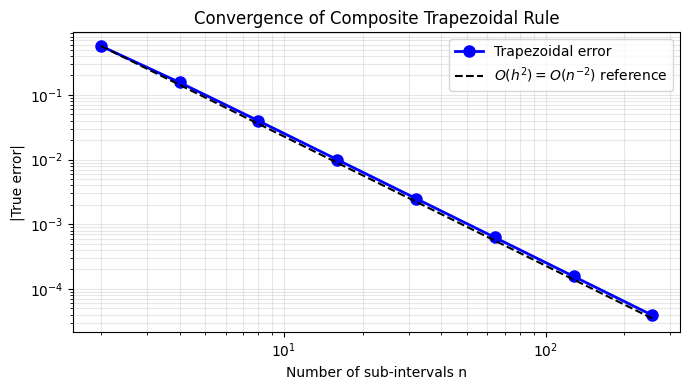

Slope (log-log) ≈ -1.98   (should be close to -2)


In [4]:
# Convergence study: error vs. n on a log-log plot
ns   = np.array([2, 4, 8, 16, 32, 64, 128, 256])
errs = np.array([abs(I_exact - composite_trap(f, a, b, n)) for n in ns])

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ns, errs, 'bo-', lw=2, ms=8, label='Trapezoidal error')
# Reference line for h^2
ax.loglog(ns, errs[0] * (ns[0]/ns)**2, 'k--', lw=1.5, label='$O(h^2) = O(n^{-2})$ reference')
ax.set(xlabel='Number of sub-intervals n', ylabel='|True error|',
       title='Convergence of Composite Trapezoidal Rule')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
print('Slope (log-log) ≈', np.polyfit(np.log(ns), np.log(errs), 1)[0].round(2),
      '  (should be close to -2)')

**Exercise 2.1:** Apply the composite trapezoidal rule to estimate
$$\int_0^\pi \sin(x)\,dx$$
whose exact value is $2.0$.

1. Evaluate for $n = 1, 2, 4, 8, 16$.
2. Plot the convergence (error vs. $n$) on a log-log scale.
3. How large must $n$ be to achieve an error smaller than $10^{-6}$?

     n               I         |error|
----------------------------------------
     1    0.0000000000       2.000e+00
     2    1.5707963268       4.292e-01
     4    1.8961188979       1.039e-01
     8    1.9742316019       2.577e-02
    16    1.9935703438       6.430e-03


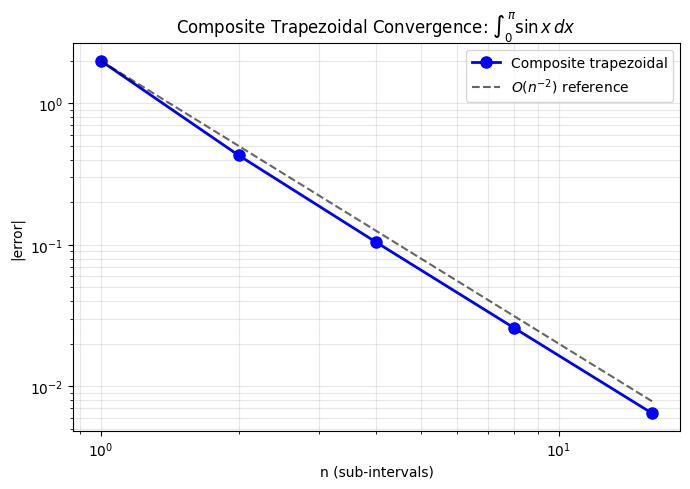


Smallest power-of-2 n with |error| < 1e-6: n = 2048, error = 3.922e-07
Theoretical bound n >= sqrt(pi^3/(12*1e-6)) ~ 1608


In [5]:
# --- YOUR CODE HERE ---
g         = lambda x: np.sin(x)
I_g_exact = 2.0

# 1. Composite trapezoidal for n = 1, 2, 4, 8, 16
ns_ex = np.array([1, 2, 4, 8, 16])
errs_ex = []
print(f'{"n":>6}  {"I":>14}  {"|error|":>14}')
print('-' * 40)
for n in ns_ex:
    I = composite_trap(g, 0, np.pi, n)
    err = abs(I - I_g_exact)
    errs_ex.append(err)
    print(f'{n:>6}  {I:>14.10f}  {err:>14.3e}')
errs_ex = np.array(errs_ex)

# 2. Log-log convergence plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(ns_ex, errs_ex, 'bo-', lw=2, ms=8, label='Composite trapezoidal')
ref = errs_ex[0] * (ns_ex[0] / ns_ex)**2
ax.loglog(ns_ex, ref, 'k--', alpha=0.6, label='$O(n^{-2})$ reference')
ax.set(xlabel='n (sub-intervals)', ylabel='|error|',
       title=r'Composite Trapezoidal Convergence: $\int_0^\pi \sin x\,dx$')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout(); plt.show()

# 3. How large must n be so |error| < 1e-6 ?
n = 2
while True:
    err = abs(composite_trap(g, 0, np.pi, n) - I_g_exact)
    if err < 1e-6:
        break
    n *= 2
print(f'\nSmallest power-of-2 n with |error| < 1e-6: n = {n}, error = {err:.3e}')
n_theory = int(np.ceil(np.sqrt(np.pi**3 / 12 / 1e-6)))
print(f'Theoretical bound n >= sqrt(pi^3/(12*1e-6)) ~ {n_theory}')


---
## 3. Simpson's Rules

### 3.1 Simpson's 1/3 Rule (parabola through 3 points)

Use a **quadratic** polynomial through $(a, f(a))$, $(m, f(m))$, $(b, f(b))$ where $m = (a+b)/2$:

$$I \approx \frac{b-a}{6}\left[f(a) + 4f(m) + f(b)\right]$$

**Truncation error** (exact for polynomials of degree $\leq 3$ — one order better than expected!):
$$E_t = -\frac{1}{90}f^{(4)}(\xi)\left(\frac{b-a}{2}\right)^5$$

### 3.2 Composite Simpson's 1/3 Rule (n must be even)

$$I \approx \frac{h}{3}\left[f(x_0) + 4f(x_1) + 2f(x_2) + 4f(x_3) + \cdots + 4f(x_{n-1}) + f(x_n)\right]$$

where $h = (b-a)/n$.  **Global error** $\propto h^4 \propto n^{-4}$.

### 3.3 Simpson's 3/8 Rule (cubic, 4 points)

$$I \approx \frac{3h}{8}\left[f(x_0) + 3f(x_1) + 3f(x_2) + f(x_3)\right], \quad h = \frac{b-a}{3}$$

Useful when $n$ is a multiple of 3 (can be combined with 1/3 rule).

In [6]:
# ---- Composite Simpson's 1/3 Rule ----
def composite_simpson13(func, a, b, n):
    """
    Composite Simpson's 1/3 rule.  n must be even.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    n    : number of sub-intervals (must be even)

    Returns
    -------
    I : float
    """
    if n % 2 != 0:
        raise ValueError('n must be even for Simpson\'s 1/3 rule')
    x = np.linspace(a, b, n + 1)
    y = func(x)
    h = (b - a) / n
    # Weights: 1, 4, 2, 4, 2, ..., 4, 1
    I = h/3 * (y[0] + 4*np.sum(y[1:-1:2]) + 2*np.sum(y[2:-2:2]) + y[-1])
    return I


# ---- Composite Simpson's 3/8 Rule ----
def composite_simpson38(func, a, b, n):
    """
    Composite Simpson's 3/8 rule.  n must be a multiple of 3.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    n    : number of sub-intervals (must be multiple of 3)

    Returns
    -------
    I : float
    """
    if n % 3 != 0:
        raise ValueError('n must be a multiple of 3 for Simpson\'s 3/8 rule')
    x = np.linspace(a, b, n + 1)
    y = func(x)
    h = (b - a) / n
    # Weights: 1, 3, 3, 2, 3, 3, 2, ..., 3, 3, 1
    w = np.ones(n + 1)
    w[0] = 1.0; w[-1] = 1.0
    w[1:-1:3] = 3.0
    w[2:-1:3] = 3.0
    w[3:-1:3] = 2.0
    return 3*h/8 * np.dot(w, y)


# Comparison table
print('Method Comparison (benchmark function, a=0, b=0.8):')
print(f'{"Method":<30}  {"n":>4}  {"I":>14}  {"error %":>10}')
print('-'*65)
for n in [2, 4, 8]:
    I_s13 = composite_simpson13(f, a, b, n)
    print(f'{"Simpson 1/3":<30}  {n:>4}  {I_s13:>14.8f}  {pct_err(I_s13):>10.6f}')
for n in [3, 6, 12]:
    I_s38 = composite_simpson38(f, a, b, n)
    print(f'{"Simpson 3/8":<30}  {n:>4}  {I_s38:>14.8f}  {pct_err(I_s38):>10.6f}')
for n in [2, 4, 8]:
    I_tr  = composite_trap(f, a, b, n)
    print(f'{"Trapezoidal":<30}  {n:>4}  {I_tr:>14.8f}  {pct_err(I_tr):>10.6f}')


Method Comparison (benchmark function, a=0, b=0.8):
Method                             n               I     error %
-----------------------------------------------------------------
Simpson 1/3                        2      1.36746667   16.644993
Simpson 1/3                        4      1.62346667    1.040312
Simpson 1/3                        8      1.63946667    0.065020
Simpson 3/8                        3      1.51917037    7.397775
Simpson 3/8                        6      1.63294815    0.462361
Simpson 3/8                       12      1.64005926    0.028898
Trapezoidal                        2      1.06880000   34.850455
Trapezoidal                        4      1.48480000    9.492848
Trapezoidal                        8      1.60080000    2.421977


<!-- SOLUTION
I = h/3 * (y[0] + 4*np.sum(y[1:-1:2]) + 2*np.sum(y[2:-2:2]) + y[-1])
-->

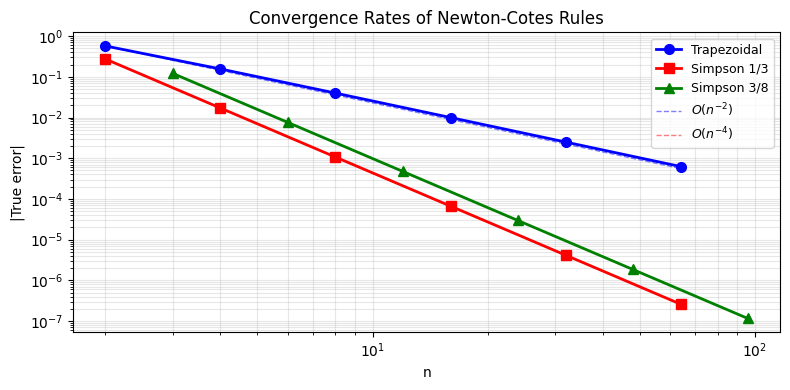

In [7]:
# Convergence comparison: Trapezoidal vs. Simpson 1/3 vs. Simpson 3/8
ns_even  = np.array([2, 4, 8, 16, 32, 64])
ns_3mult = np.array([3, 6, 12, 24, 48, 96])

err_trap = np.array([abs(I_exact - composite_trap(f, a, b, n)) for n in ns_even])
err_s13  = np.array([abs(I_exact - composite_simpson13(f, a, b, n)) for n in ns_even])
err_s38  = np.array([abs(I_exact - composite_simpson38(f, a, b, n)) for n in ns_3mult])

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(ns_even,  err_trap, 'bo-', lw=2, ms=7, label='Trapezoidal')
ax.loglog(ns_even,  err_s13,  'rs-', lw=2, ms=7, label="Simpson 1/3")
ax.loglog(ns_3mult, err_s38,  'g^-', lw=2, ms=7, label='Simpson 3/8')
# Reference lines
ax.loglog(ns_even, err_trap[0]*(ns_even[0]/ns_even)**2, 'b--', lw=1, alpha=0.5, label='$O(n^{-2})$')
ax.loglog(ns_even, err_s13[0]*(ns_even[0]/ns_even)**4, 'r--', lw=1, alpha=0.5, label='$O(n^{-4})$')
ax.set(xlabel='n', ylabel='|True error|', title='Convergence Rates of Newton-Cotes Rules')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

**Exercise 3.1:** Use composite Simpson's 1/3 rule to integrate
$$\int_0^2 x\,e^x\,dx$$
whose exact value is $e^2 + 1 \approx 8.38906$.

1. Evaluate for $n = 2, 4, 8, 16$.
2. Verify that the error decreases approximately as $O(n^{-4})$.
3. Compare with the composite trapezoidal rule at the same $n$ values — which is more efficient?

   n       Simpson 1/3       |err_S|       Trapezoidal       |err_T|
----------------------------------------------------------------------
   2      8.5504131706     1.614e-01     10.1073379274     1.718e+00
   4      8.4003754697     1.132e-02      8.8271160841     4.381e-01
   8      8.3897852769     7.292e-04      8.4991179787     1.101e-01
  16      8.3891020225     4.592e-05      8.4166060116     2.755e-02

Simpson error ratios (should approach 16 = 2^4):
   [14.25495064 15.52346862 15.87806614]


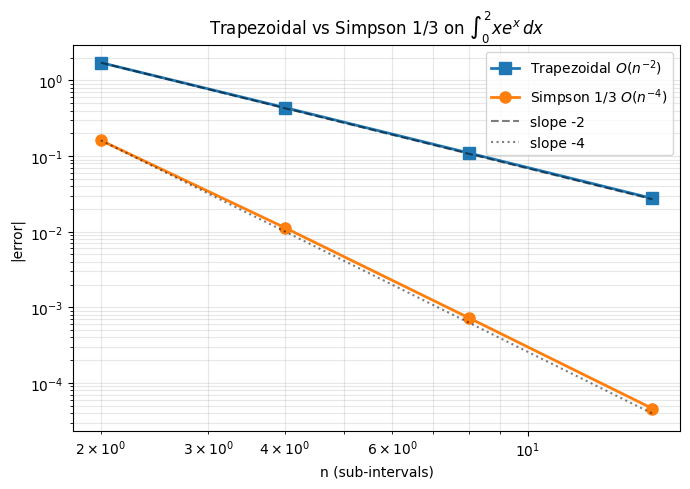


Simpson 1/3 is far more efficient: at n=16 it reaches 4.6e-05 vs 2.8e-02 for trapezoidal.


In [8]:
# --- YOUR CODE HERE ---
h_func    = lambda x: x * np.exp(x)
I_h_exact = np.e**2 + 1   # = e^2 + 1 ~ 8.38906

# 1. Composite Simpson 1/3 + Trapezoidal for n = 2, 4, 8, 16
ns_h = np.array([2, 4, 8, 16])
err_simp = []
err_trap = []
print(f'{"n":>4}  {"Simpson 1/3":>16}  {"|err_S|":>12}  '
      f'{"Trapezoidal":>16}  {"|err_T|":>12}')
print('-' * 70)
for n in ns_h:
    Is = composite_simpson13(h_func, 0, 2, n)
    It = composite_trap(h_func, 0, 2, n)
    es = abs(Is - I_h_exact); err_simp.append(es)
    et = abs(It - I_h_exact); err_trap.append(et)
    print(f'{n:>4}  {Is:>16.10f}  {es:>12.3e}  {It:>16.10f}  {et:>12.3e}')
err_simp = np.array(err_simp); err_trap = np.array(err_trap)

# 2. Verify O(n^-4) convergence: ratio of successive errors should be ~ 16
print('\nSimpson error ratios (should approach 16 = 2^4):')
print('  ', err_simp[:-1] / err_simp[1:])

# 3. Plot comparison
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(ns_h, err_trap, 's-', lw=2, ms=8, label='Trapezoidal $O(n^{-2})$')
ax.loglog(ns_h, err_simp, 'o-', lw=2, ms=8, label="Simpson 1/3 $O(n^{-4})$")
ax.loglog(ns_h, err_trap[0]*(ns_h[0]/ns_h)**2.0, 'k--', alpha=0.5, label='slope -2')
ax.loglog(ns_h, err_simp[0]*(ns_h[0]/ns_h)**4.0, 'k:',  alpha=0.5, label='slope -4')
ax.set(xlabel='n (sub-intervals)', ylabel='|error|',
       title=r'Trapezoidal vs Simpson 1/3 on $\int_0^2 x e^x\,dx$')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout(); plt.show()

print('\nSimpson 1/3 is far more efficient: at n=16 it reaches '
      f'{err_simp[-1]:.1e} vs {err_trap[-1]:.1e} for trapezoidal.')


---
## 4. Richardson Extrapolation and Romberg Integration

### 4.1 Richardson Extrapolation

If the error of a method with step $h$ is $E(h) = C h^p + O(h^{p+2})$, then combining two estimates
$I(h)$ and $I(h/2)$ cancels the dominant error term:

$$I_{\text{extrap}} = \frac{2^p\, I(h/2) - I(h)}{2^p - 1}$$

For the trapezoidal rule ($p = 2$):
$$I_{\text{extrap}} = \frac{4\, I(h/2) - I(h)}{3}$$

This yields **Simpson's 1/3 rule** — Richardson extrapolation on Trapezoidal = Simpson!

### 4.2 Romberg Integration Table

Romberg integration applies Richardson extrapolation **repeatedly**, building a triangular table:

| Level | $h$ | $R_{k,0}$ (trap) | $R_{k,1}$ | $R_{k,2}$ | $R_{k,3}$ |
|-------|-----|-------------------|-----------|-----------|----------|
| 0 | $h_0 = b-a$ | trap, $n=1$ | | | |
| 1 | $h_0/2$ | trap, $n=2$ | extrap | | |
| 2 | $h_0/4$ | trap, $n=4$ | extrap | extrap | |
| 3 | $h_0/8$ | trap, $n=8$ | extrap | extrap | extrap |

**Extrapolation formula** (column $j > 0$):
$$R_{k,j} = \frac{4^j\,R_{k,\,j-1} - R_{k-1,\,j-1}}{4^j - 1}$$

In [9]:
def romberg(func, a, b, max_level=6, tol=1e-10):
    """
    Romberg integration.

    Parameters
    ----------
    func      : callable
    a, b      : integration limits
    max_level : maximum number of refinement levels (table size = max_level+1)
    tol       : convergence tolerance on the last diagonal entry

    Returns
    -------
    R     : 2-D array  (Romberg table)
    n_lvl : int        (number of levels used)
    """
    R = np.zeros((max_level + 1, max_level + 1))

    # First column: composite trapezoidal with n = 2^k sub-intervals
    n = 1
    R[0, 0] = composite_trap(func, a, b, n)

    for k in range(1, max_level + 1):
        n = 2**k
        R[k, 0] = composite_trap(func, a, b, n)

        # Richardson extrapolation to fill row k
        for j in range(1, k + 1):
            R[k, j] = (4**j * R[k, j-1] - R[k-1, j-1]) / (4**j - 1)

        # Convergence check on the latest best estimate
        if k >= 1 and abs(R[k, k] - R[k-1, k-1]) < tol:
            return R[:k+1, :k+1], k

    return R, max_level


R_table, n_lvl = romberg(f, a, b, max_level=6)
print('Romberg Table:')
print(f'{"Level k":>7}  {"n=2^k":>6}  '
      + '  '.join([f'R[k,{j}]'.center(14) for j in range(n_lvl+1)]))
print('-'*(10 + 18*(n_lvl+1)))
for k in range(n_lvl + 1):
    row = '  '.join([f'{R_table[k,j]:14.10f}' if j <= k else ' '*14
                    for j in range(n_lvl+1)])
    print(f'{k:>7}  {2**k:>6}  {row}')
print(f'\nBest estimate R[{n_lvl},{n_lvl}] = {R_table[n_lvl,n_lvl]:.12f}')
print(f'Exact                  = {I_exact:.12f}')
print(f'Error                  = {abs(R_table[n_lvl,n_lvl]-I_exact):.2e}')


Romberg Table:
Level k   n=2^k      R[k,0]          R[k,1]          R[k,2]          R[k,3]    
----------------------------------------------------------------------------------
      0       1    0.1728000000                                                
      1       2    1.0688000000    1.3674666667                                
      2       4    1.4848000000    1.6234666667    1.6405333333                
      3       8    1.6008000000    1.6394666667    1.6405333333    1.6405333333

Best estimate R[3,3] = 1.640533333333
Exact                  = 1.640533333333
Error                  = 2.89e-15


<!-- SOLUTION
R[k, 0] = composite_trap(func, a, b, n)
R[k, j] = (4**j * R[k, j-1] - R[k-1, j-1]) / (4**j - 1)
-->

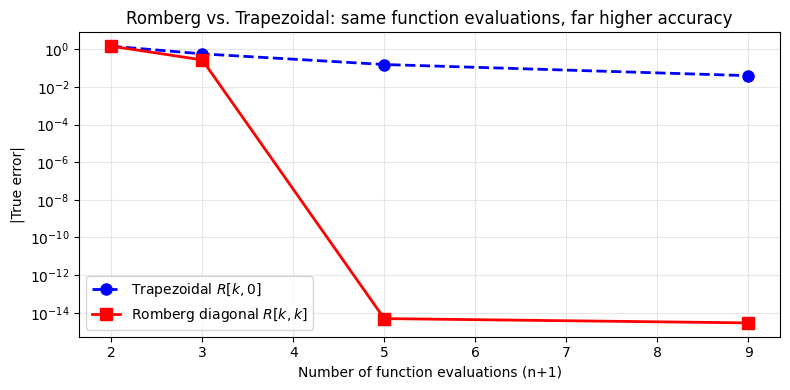

In [10]:
# Visualise Romberg convergence vs. trapezoidal
diag_err  = [abs(I_exact - R_table[k, k]) for k in range(n_lvl + 1)]
trap_err  = [abs(I_exact - R_table[k, 0]) for k in range(n_lvl + 1)]
func_evals = [2**k + 1 for k in range(n_lvl + 1)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(func_evals, trap_err,  'bo--', lw=2, ms=8, label='Trapezoidal $R[k,0]$')
ax.semilogy(func_evals, diag_err,  'rs-',  lw=2, ms=8, label='Romberg diagonal $R[k,k]$')
ax.set(xlabel='Number of function evaluations (n+1)', ylabel='|True error|',
       title='Romberg vs. Trapezoidal: same function evaluations, far higher accuracy')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

열을 따라가면 차수가 $2(j+1)$로 올라가고,
행을 따라가면 $h_k$가 $1/2$씩 작아짐.

**Exercise 4.1:** Apply Romberg integration to
$$\int_0^1 \frac{4}{1+x^2}\,dx = \pi$$

1. Run `romberg` with `max_level=8` and print the full table.
2. How many levels are needed to achieve $|R[k,k] - \pi| < 10^{-10}$?
3. Compare the number of function evaluations required by Romberg vs. composite Simpson's 1/3 to achieve the same accuracy.

In [11]:
# --- YOUR CODE HERE ---
pi_func = lambda x: 4.0 / (1.0 + x**2)

# 1. Romberg with max_level = 8 (full table)
R, n_lvl = romberg(pi_func, 0, 1, max_level=8, tol=0.0)
print('Romberg Table (each row k uses n = 2^k sub-intervals):')
print(f'{"k":>3} {"n":>4}  ' + '  '.join(f'R[k,{j}]'.center(16) for j in range(n_lvl+1)))
print('-' * (10 + 18*(n_lvl+1)))
for k in range(n_lvl + 1):
    row = '  '.join(f'{R[k,j]:16.13f}' if j <= k else ' '*16 for j in range(n_lvl+1))
    print(f'{k:>3} {2**k:>4}  {row}')

# 2. Smallest k with |R[k,k] - pi| < 1e-10
print('\nDiagonal accuracy:')
needed_k = None
for k in range(n_lvl + 1):
    err = abs(R[k, k] - np.pi)
    print(f'  R[{k},{k}] = {R[k,k]:.15f},  |err| = {err:.2e}')
    if needed_k is None and err < 1e-10:
        needed_k = k
print(f'\nFirst k with |R[k,k]-pi| < 1e-10:  k = {needed_k}, '
      f'using n = {2**needed_k} sub-intervals (= {2**needed_k + 1} func evals).')

# 3. How many evals does Simpson 1/3 need to reach the same accuracy?
n = 2
while abs(composite_simpson13(pi_func, 0, 1, n) - np.pi) >= 1e-10:
    n += 2
print(f'Simpson 1/3 needs n = {n} sub-intervals = {n+1} function evaluations.')
romberg_evals = 2**needed_k + 1
print(f'\nFunction evaluations: Romberg = {romberg_evals}, '
      f'Simpson = {n+1}.  Romberg is ~{(n+1)/romberg_evals:.1f}x more efficient.')


Romberg Table (each row k uses n = 2^k sub-intervals):
  k    n       R[k,0]            R[k,1]            R[k,2]            R[k,3]            R[k,4]            R[k,5]            R[k,6]            R[k,7]            R[k,8]     
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  0    1   3.0000000000000                                                                                                                                                
  1    2   3.1000000000000   3.1333333333333                                                                                                                              
  2    4   3.1311764705882   3.1415686274510   3.1421176470588                                                                                                            
  3    8   3.1389884944911   3.1415925024587   3.1415940941259   3.1415857837619        

---
## 5. Gauss-Legendre Quadrature

### 5.1 Big Idea

Newton-Cotes rules fix the **nodes** at equally spaced points and optimize the **weights**.
**Gauss quadrature** optimizes **both** nodes and weights simultaneously:

$$\int_{-1}^{1} f(x)\,dx \approx \sum_{i=1}^{n} w_i\, f(x_i)$$

With $n$ nodes, the formula is **exact for all polynomials of degree $\leq 2n-1$** — the highest possible for any $n$-point formula.

### 5.2 Change of Variable

The Gauss-Legendre nodes $x_i \in [-1, 1]$ and weights $w_i$ are derived for the standard interval.
To integrate over $[a, b]$, use the linear substitution:

$$t = \frac{b-a}{2}\,x + \frac{a+b}{2}, \quad dt = \frac{b-a}{2}\,dx$$

$$\int_a^b f(t)\,dt = \frac{b-a}{2}\sum_{i=1}^{n} w_i\, f\!\left(\frac{b-a}{2}\,x_i + \frac{a+b}{2}\right)$$

### 5.3 Gauss-Legendre Nodes and Weights

The nodes $x_i$ are the **roots of the Legendre polynomial** $P_n(x)$:

| $n$ | Nodes $x_i$ | Weights $w_i$ |
|-----|------------|---------------|
| 1 | $0$ | $2$ |
| 2 | $\pm 1/\sqrt{3} \approx \pm 0.5774$ | $1, 1$ |
| 3 | $0$, $\pm\sqrt{3/5} \approx \pm 0.7746$ | $8/9$, $5/9$, $5/9$ |
| 4 | $\pm 0.3400$, $\pm 0.8611$ | $0.6521$, $0.6521$, $0.3479$, $0.3479$ |
| 5 | $0$, $\pm 0.5385$, $\pm 0.9062$ | $0.5689$, $0.4786$, $0.4786$, $0.2369$, $0.2369$ |

`numpy.polynomial.legendre.leggauss(n)` returns exact nodes and weights.

Gauss-Legendre nodes and weights (standard interval [-1,1]):
  n=1: nodes = [0.],  weights = [2.]
        sum(weights) = 2.0000000000  (should be 2.0)
  n=2: nodes = [-0.57735  0.57735],  weights = [1. 1.]
        sum(weights) = 2.0000000000  (should be 2.0)
  n=3: nodes = [-0.774597  0.        0.774597],  weights = [0.555556 0.888889 0.555556]
        sum(weights) = 2.0000000000  (should be 2.0)
  n=4: nodes = [-0.861136 -0.339981  0.339981  0.861136],  weights = [0.347855 0.652145 0.652145 0.347855]
        sum(weights) = 2.0000000000  (should be 2.0)
  n=5: nodes = [-0.90618  -0.538469  0.        0.538469  0.90618 ],  weights = [0.236927 0.478629 0.568889 0.478629 0.236927]
        sum(weights) = 2.0000000000  (should be 2.0)


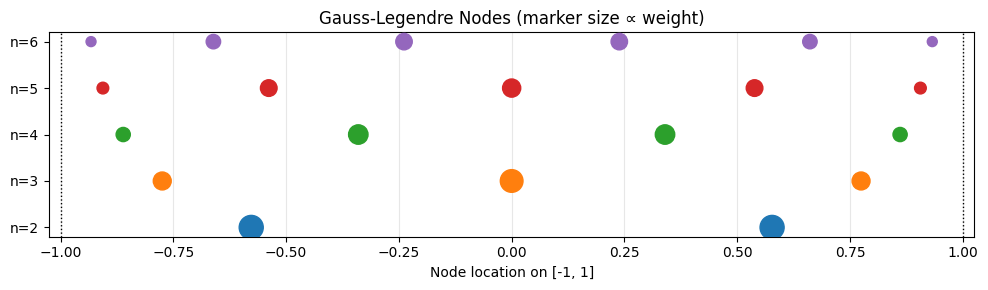

In [12]:
# Print GL nodes and weights for n = 1..5
print('Gauss-Legendre nodes and weights (standard interval [-1,1]):')
for n in range(1, 6):
    xi, wi = leggauss(n)
    print(f'  n={n}: nodes = {np.round(xi,6)},  weights = {np.round(wi,6)}')
    print(f'        sum(weights) = {wi.sum():.10f}  (should be 2.0)')

# Visualise nodes on [-1,1]
fig, ax = plt.subplots(figsize=(10, 3))
for row, n in enumerate([2, 3, 4, 5, 6]):
    xi, wi = leggauss(n)
    ax.scatter(xi, np.full(n, row), s=wi*300, c=f'C{row}',
               zorder=5, label=f'n={n}')
ax.set_yticks(range(5)); ax.set_yticklabels([f'n={n}' for n in [2,3,4,5,6]])
ax.set(xlabel='Node location on [-1, 1]',
       title='Gauss-Legendre Nodes (marker size ∝ weight)')
ax.axvline(-1, color='k', ls=':', lw=1); ax.axvline(1, color='k', ls=':', lw=1)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

In [13]:
def gauss_legendre(func, a, b, n):
    """
    Gauss-Legendre quadrature on [a, b] with n nodes.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    n    : number of Gauss-Legendre nodes

    Returns
    -------
    I : float
    """
    # Get nodes and weights on [-1, 1]
    xi, wi = leggauss(n)

    # Map nodes from [-1,1] to [a,b]: t = (b-a)/2 * xi + (a+b)/2
    t  = (b - a)/2 * xi + (a + b)/2
    I  = (b - a)/2 * np.dot(wi, func(t))
    return I


# Test: benchmark function
print('Gauss-Legendre Quadrature (benchmark function):')
print(f'{"n":>4}  {"I":>14}  {"error %":>12}  {"func evals":>10}')
print('-'*50)
for n in range(1, 7):
    I_gl = gauss_legendre(f, a, b, n)
    print(f'{n:>4}  {I_gl:>14.10f}  {pct_err(I_gl):>12.2e}  {n:>10}')


Gauss-Legendre Quadrature (benchmark function):
   n               I       error %  func evals
--------------------------------------------------
   1    1.9648000000      1.98e+01           1
   2    1.8225777778      1.11e+01           2
   3    1.6405333333      2.71e-13           3
   4    1.6405333333      1.35e-13           4
   5    1.6405333333      2.30e-13           5
   6    1.6405333333      2.71e-14           6


<!-- SOLUTION
t  = (b - a)/2 * xi + (a + b)/2
I  = (b - a)/2 * np.dot(wi, func(t))
-->

### 5.4 Why does $n = 3$ give zero error?

The benchmark $f(x)$ is a degree-5 polynomial. Gauss-Legendre with $n$ nodes is **exact** for polynomials of degree $\leq 2n-1$.

| $n$ | Exact for degree $\leq$ |
|-----|-------------------------|
| 1 | 1 |
| 2 | 3 |
| **3** | **5** ← benchmark is degree 5 |
| 4 | 7 |

So $n = 3$ is sufficient for exact integration of our degree-5 polynomial — with only **3 function evaluations**! Compare this to Simpson's $n = 8$ (9 evaluations) needed for similar accuracy.

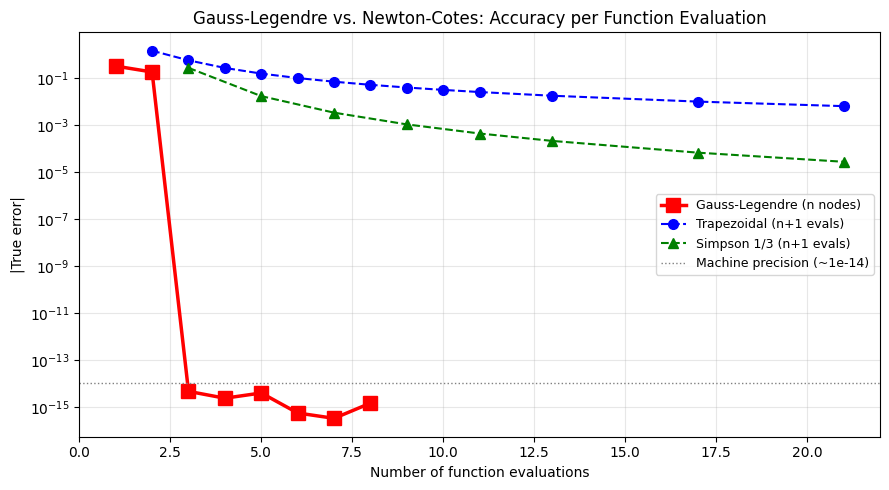

Gauss-Legendre reaches machine precision with 3 evaluations!
Trapezoidal needs ~64 evaluations for similar accuracy.


In [14]:
# Accuracy vs. function evaluations: GL vs. Newton-Cotes methods
fig, ax = plt.subplots(figsize=(9, 5))

# Gauss-Legendre
ns_gl  = np.arange(1, 9)
err_gl = np.array([abs(I_exact - gauss_legendre(f, a, b, n)) + 1e-16 for n in ns_gl])
ax.semilogy(ns_gl, err_gl, 'rs-', lw=2.5, ms=10, label='Gauss-Legendre (n nodes)')

# Trapezoidal
ns_nc  = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 16, 20])
err_nc = np.array([abs(I_exact - composite_trap(f, a, b, n)) + 1e-16 for n in ns_nc])
ax.semilogy(ns_nc + 1, err_nc, 'bo--', lw=1.5, ms=7, label='Trapezoidal (n+1 evals)')

# Simpson 1/3
ns_s  = np.array([2, 4, 6, 8, 10, 12, 16, 20])
err_s = np.array([abs(I_exact - composite_simpson13(f, a, b, n)) + 1e-16 for n in ns_s])
ax.semilogy(ns_s + 1, err_s, 'g^--', lw=1.5, ms=7, label="Simpson 1/3 (n+1 evals)")

ax.axhline(1e-14, color='gray', ls=':', lw=1, label='Machine precision (~1e-14)')
ax.set(xlabel='Number of function evaluations', ylabel='|True error|',
       title='Gauss-Legendre vs. Newton-Cotes: Accuracy per Function Evaluation')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

print('Gauss-Legendre reaches machine precision with 3 evaluations!')
print('Trapezoidal needs ~64 evaluations for similar accuracy.')

### 5.5 Composite Gauss-Legendre

For non-polynomial or irregular functions, applying GL on the whole interval may converge slowly.
**Composite GL** divides $[a,b]$ into $m$ sub-intervals and applies $n$-point GL on each:
total function evaluations = $m \times n$.

In [15]:
def composite_gauss_legendre(func, a, b, m, n):
    """
    Composite Gauss-Legendre: m sub-intervals, n GL points each.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    m    : number of sub-intervals
    n    : number of GL nodes per sub-interval

    Returns
    -------
    I : float
    """
    xi, wi = leggauss(n)
    breakpoints = np.linspace(a, b, m + 1)
    I = 0.0
    for k in range(m):
        ak, bk = breakpoints[k], breakpoints[k+1]
        t  = (bk - ak)/2 * xi + (ak + bk)/2
        I += (bk - ak)/2 * np.dot(wi, func(t))
    return I

# Demonstrate on a non-polynomial: sin(1/x)^2  (highly oscillatory near 0)
s_func  = lambda x: np.sin(1.0 / (x + 0.1))**2
I_ref, _ = integrate.quad(s_func, 0, 1)
print(f'Reference (scipy): I = {I_ref:.10f}')
print(f'\n{"m×n":>6}  {"m":>4}  {"n":>4}  {"I":>14}  {"error":>12}')
print('-'*50)
for m, n in [(1,4), (2,4), (4,4), (8,4), (1,8), (4,8)]:
    I_cgl = composite_gauss_legendre(s_func, 0, 1, m, n)
    print(f'{m*n:>6}  {m:>4}  {n:>4}  {I_cgl:>14.10f}  {abs(I_ref-I_cgl):>12.2e}')


Reference (scipy): I = 0.6877412270

   m×n     m     n               I         error
--------------------------------------------------
     4     1     4    0.6180165568      6.97e-02
     8     2     4    0.7240326701      3.63e-02
    16     4     4    0.6820045672      5.74e-03
    32     8     4    0.6852653783      2.48e-03
     8     1     8    0.7245846393      3.68e-02
    32     4     8    0.6884354974      6.94e-04


<!-- SOLUTION
t  = (bk - ak)/2 * xi + (ak + bk)/2
I += (bk - ak)/2 * np.dot(wi, func(t))
-->

**Exercise 5.1:** Use `gauss_legendre` to evaluate
$$\int_0^1 e^{-x^2}\,dx$$
whose reference value (from `scipy.integrate.quad`) is approximately $0.74682413$.

1. Test $n = 1, 2, 3, 4, 5, 6, 7, 8$.
2. At which $n$ does the error drop below $10^{-8}$?
3. Why does Gauss-Legendre not reach machine precision quickly here, unlike for the degree-5 polynomial?

Closed-form reference (sqrt(pi)/2 * erf(1)) = 0.7468241328124269
scipy.integrate.quad value                  = 0.7468241328124271
(quad - closed_form)                         = 2.22e-16

  n                     I         |error|
--------------------------------------------
  1    0.7788007830714049       3.198e-02
  2    0.7465946882828597       2.294e-04
  3    0.7468145841912558       9.549e-06
  4    0.7468244681309939       3.353e-07
  5    0.7468241267662481       6.046e-09
  6    0.7468241328901555       7.773e-11
  7    0.7468241328116383       7.886e-13
  8    0.7468241328124336       6.772e-15

First n with |error| < 1e-08:  n = 5, error = 6.05e-09


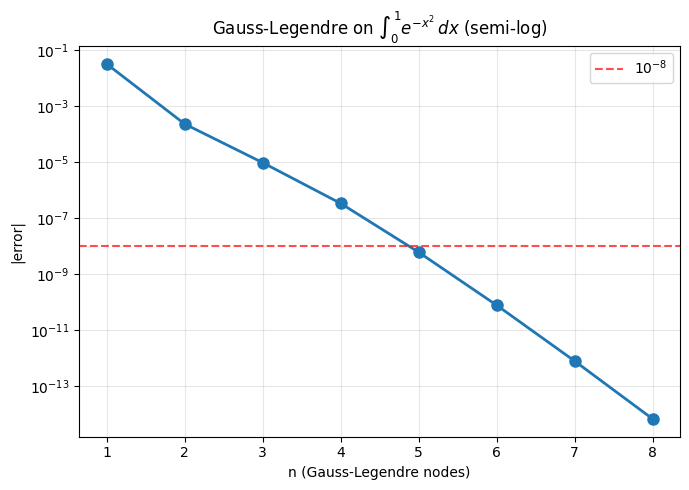


Why is convergence not instant (unlike for the degree-5 polynomial)?
 - GL with n nodes is exact ONLY for polynomials of degree <= 2n-1.
 - exp(-x^2) is analytic but not a polynomial: GL converges geometrically
   (spectral) but no finite n makes the error exactly zero.
 - The benchmark f(x) was a degree-5 polynomial, so GL with n = 3
   (exact through degree 5) integrates it exactly to machine precision.


In [16]:
# --- YOUR CODE HERE ---
gauss_func = lambda x: np.exp(-x**2)

# Closed-form reference: ∫_0^1 e^{-x^2} dx = (sqrt(pi)/2) * erf(1)
from scipy.special import erf
I_gauss_ref = 0.5 * np.sqrt(np.pi) * erf(1.0)
I_quad, _   = integrate.quad(gauss_func, 0, 1)
print(f'Closed-form reference (sqrt(pi)/2 * erf(1)) = {I_gauss_ref:.16f}')
print(f'scipy.integrate.quad value                  = {I_quad:.16f}')
print(f'(quad - closed_form)                         = {I_quad - I_gauss_ref:.2e}')

# 1. GL for n = 1..8
ns_gl = np.arange(1, 9)
err_gl = []
print(f'\n{"n":>3}  {"I":>20}  {"|error|":>14}')
print('-' * 44)
for n in ns_gl:
    I = gauss_legendre(gauss_func, 0, 1, n)
    e = abs(I - I_gauss_ref); err_gl.append(e)
    print(f'{n:>3}  {I:>20.16f}  {e:>14.3e}')
err_gl = np.array(err_gl)

# 2. Smallest n with error below 1e-8
threshold = 1e-8
idx = np.where(err_gl < threshold)[0]
if idx.size:
    print(f'\nFirst n with |error| < {threshold:g}:  n = {ns_gl[idx[0]]}, '
          f'error = {err_gl[idx[0]]:.2e}')

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(ns_gl, np.maximum(err_gl, 1e-17), 'o-', lw=2, ms=8, color='C0')
ax.axhline(threshold, color='r', ls='--', alpha=0.7, label=r'$10^{-8}$')
ax.set(xlabel='n (Gauss-Legendre nodes)', ylabel='|error|',
       title=r'Gauss-Legendre on $\int_0^1 e^{-x^2}\,dx$ (semi-log)')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# 3. Discussion
msg = (
    "Why is convergence not instant (unlike for the degree-5 polynomial)?\n"
    " - GL with n nodes is exact ONLY for polynomials of degree <= 2n-1.\n"
    " - exp(-x^2) is analytic but not a polynomial: GL converges geometrically\n"
    "   (spectral) but no finite n makes the error exactly zero.\n"
    " - The benchmark f(x) was a degree-5 polynomial, so GL with n = 3\n"
    "   (exact through degree 5) integrates it exactly to machine precision."
)
print('\n' + msg)


---
## 6. Gauss-Lobatto Quadrature

### 6.1 Motivation

Gauss-Legendre nodes are **interior** points of $[-1,1]$. Sometimes you need to **include the endpoints** $\pm 1$:

- Multidomain spectral methods (fields must match at element boundaries)
- Problems where endpoint evaluations are already known
- Some adaptive quadrature schemes (e.g., Gauss-Kronrod, used by `scipy.integrate.quad`)

**Gauss-Lobatto-Legendre (GLL)** quadrature fixes both endpoints $x_1 = -1$, $x_n = +1$ and optimizes the $n-2$ interior nodes:

$$\int_{-1}^{1} f(x)\,dx \approx \sum_{i=1}^{n} w_i\, f(x_i)$$

With $n$ nodes (including the two endpoints), the formula is **exact for polynomials of degree $\leq 2n-3$** (two orders less than GL because endpoints are fixed).

### 6.2 Lobatto Nodes and Weights

Interior nodes are roots of $P'_{n-1}(x)$ (derivative of the Legendre polynomial of degree $n-1$).

| $n$ | Nodes (including $\pm 1$) | Weights |
|-----|---------------------------|--------|
| 2 | $-1, +1$ | $1, 1$ |
| 3 | $-1, 0, +1$ | $1/3, 4/3, 1/3$ |
| 4 | $-1, \pm 1/\sqrt{5}, +1$ | $1/6, 5/6, 5/6, 1/6$ |
| 5 | $-1, \pm\sqrt{3/7}, 0, +1$ | $1/10, 49/90, 32/45, 49/90, 1/10$ |

**Endpoint weight** is always $w_1 = w_n = 2/(n(n-1))$.

### 6.3 Computing Lobatto Nodes and Weights

The $n$-point GLL nodes can be found by computing the eigenvalues of the **symmetric tridiagonal Jacobi matrix** (companion matrix of $P'_{n-1}$).

In [17]:
def lobatto_nodes_weights(n):
    """
    Compute n-point Gauss-Lobatto-Legendre (GLL) nodes and weights on [-1, 1].

    The endpoints ±1 are always included.
    Interior nodes are roots of P\'_{n-1}(x).
    Weights: w_i = 2 / [n(n-1) * P_{n-1}(x_i)^2].

    Parameters
    ----------
    n : int >= 2 — number of quadrature nodes

    Returns
    -------
    x, w : arrays of length n (sorted ascending)
    """
    if n < 2:
        raise ValueError('Lobatto quadrature requires n >= 2')
    if n == 2:
        return np.array([-1.0, 1.0]), np.array([1.0, 1.0])

    # Interior nodes are the zeros of P\'_{n-1}(x)
    from numpy.polynomial.legendre import Legendre, legval
    P_nm1 = Legendre.basis(n - 1)          # Legendre polynomial P_{n-1}
    x_interior = np.sort(P_nm1.deriv().roots().real)

    # Full node set including endpoints
    x = np.concatenate([[-1.0], x_interior, [1.0]])

    # Weights: w_i = 2 / [n*(n-1) * (P_{n-1}(x_i))^2]
    c = np.zeros(n); c[n - 1] = 1.0        # coefficient vector for P_{n-1}
    Pn1 = legval(x, c)
    w = 2.0 / (n * (n - 1) * Pn1**2)
    return x, w


# Verify: sum of weights should equal 2.0
print('Gauss-Lobatto nodes and weights (standard interval [-1,1]):')
for n in range(2, 8):
    xi, wi = lobatto_nodes_weights(n)
    print(f'  n={n}: nodes = {np.round(xi,6)}')
    print(f'        weights = {np.round(wi,6)},  sum = {wi.sum():.10f}')
    print()


Gauss-Lobatto nodes and weights (standard interval [-1,1]):
  n=2: nodes = [-1.  1.]
        weights = [1. 1.],  sum = 2.0000000000

  n=3: nodes = [-1.  0.  1.]
        weights = [0.333333 1.333333 0.333333],  sum = 2.0000000000

  n=4: nodes = [-1.       -0.447214  0.447214  1.      ]
        weights = [0.166667 0.833333 0.833333 0.166667],  sum = 2.0000000000

  n=5: nodes = [-1.       -0.654654 -0.        0.654654  1.      ]
        weights = [0.1      0.544444 0.711111 0.544444 0.1     ],  sum = 2.0000000000

  n=6: nodes = [-1.       -0.765055 -0.285232  0.285232  0.765055  1.      ]
        weights = [0.066667 0.378475 0.554858 0.554858 0.378475 0.066667],  sum = 2.0000000000

  n=7: nodes = [-1.       -0.830224 -0.468849 -0.        0.468849  0.830224  1.      ]
        weights = [0.047619 0.276826 0.431745 0.487619 0.431745 0.276826 0.047619],  sum = 2.0000000000



In [18]:
def gauss_lobatto(func, a, b, n):
    """
    Gauss-Lobatto quadrature on [a, b] with n nodes (endpoints included).

    Parameters
    ----------
    func : callable
    a, b : integration limits
    n    : number of GLL nodes (n >= 2; endpoints ±1 are always included)

    Returns
    -------
    I : float
    """
    xi, wi = lobatto_nodes_weights(n)
    # Map nodes from [-1,1] to [a,b]
    t  = (b - a)/2 * xi + (a + b)/2
    I  = (b - a)/2 * np.dot(wi, func(t))
    return I


# Test on benchmark function
print('Gauss-Lobatto Quadrature (benchmark function):')
print(f'{"n":>4}  {"exact deg":<12}  {"I":>14}  {"error %":>12}')
print('-'*50)
for n in range(2, 9):
    I_lo = gauss_lobatto(f, a, b, n)
    exact_deg = 2*n - 3
    print(f'{n:>4}  {exact_deg:<12}  {I_lo:>14.10f}  {pct_err(I_lo):>12.2e}')


Gauss-Lobatto Quadrature (benchmark function):
   n  exact deg                  I       error %
--------------------------------------------------
   2  1               0.1728000000      8.95e+01
   3  3               1.3674666667      1.66e+01
   4  5               1.6405333333      5.41e-14
   5  7               1.6405333333      5.41e-14
   6  9               1.6405333333      9.47e-14
   7  11              1.6405333333      8.12e-14
   8  13              1.6405333333      4.06e-13


<!-- SOLUTION
t  = (b - a)/2 * xi + (a + b)/2
I  = (b - a)/2 * np.dot(wi, func(t))
-->

### 6.4 Comparison: Gauss-Legendre vs. Gauss-Lobatto

| Property | Gauss-Legendre | Gauss-Lobatto |
|----------|---------------|---------------|
| Endpoint nodes? | **No** (interior only) | **Yes** ($\pm 1$ always included) |
| Exact degree | $\leq 2n-1$ | $\leq 2n-3$ |
| Best for | Maximum accuracy, smooth $f$ | Spectral elements, nested rules |
| Gauss-Kronrod? | Base rule | Extension rule |
| Nesting | Not naturally nested | $n$-point set $\subset$ $(2n-1)$-point set |

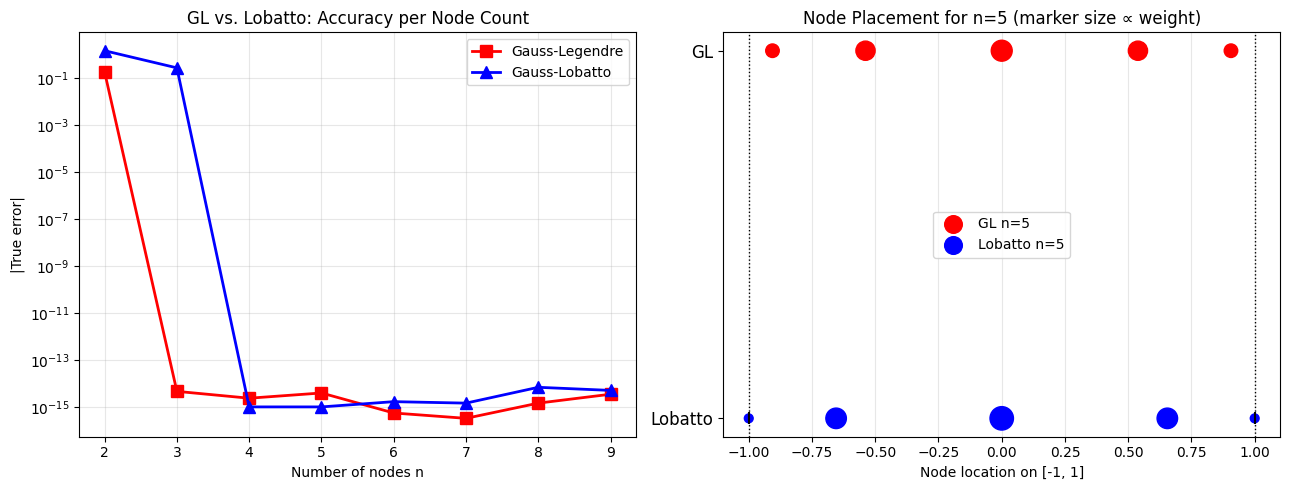

In [19]:
# Direct comparison: GL vs. Lobatto on the benchmark function
ns = np.arange(2, 10)
err_gl_list  = [abs(I_exact - gauss_legendre(f, a, b, n)) + 1e-16 for n in ns]
err_lo_list  = [abs(I_exact - gauss_lobatto(f, a, b, n)) + 1e-16 for n in ns]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.semilogy(ns, err_gl_list, 'rs-', lw=2, ms=8, label='Gauss-Legendre')
ax.semilogy(ns, err_lo_list, 'b^-', lw=2, ms=8, label='Gauss-Lobatto')
ax.set(xlabel='Number of nodes n', ylabel='|True error|',
       title='GL vs. Lobatto: Accuracy per Node Count')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

# Visualise node placement
ax = axes[1]
n_vis = 5
xi_gl, wi_gl = leggauss(n_vis)
xi_lo, wi_lo = lobatto_nodes_weights(n_vis)

ax.scatter(xi_gl, np.ones(n_vis)*1,  s=wi_gl*400, c='red',  zorder=5, label=f'GL n={n_vis}')
ax.scatter(xi_lo, np.ones(n_vis)*0,  s=wi_lo*400, c='blue', zorder=5, label=f'Lobatto n={n_vis}')
ax.scatter([-1, 1], [0, 0], s=80, c='k', marker='|', zorder=6)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Lobatto', 'GL'], fontsize=12)
ax.set(xlabel='Node location on [-1, 1]',
       title=f'Node Placement for n={n_vis} (marker size ∝ weight)')
ax.axvline(-1, color='k', ls=':', lw=1); ax.axvline(1, color='k', ls=':', lw=1)
ax.legend(fontsize=10); ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout(); plt.show()

### 6.5 Composite Gauss-Lobatto

A key advantage of Lobatto: adjacent sub-intervals **share endpoint nodes**, so composite Lobatto reuses evaluations at interval boundaries.

In [20]:
def composite_gauss_lobatto(func, a, b, m, n):
    """
    Composite Gauss-Lobatto: m sub-intervals, n GLL points each.
    Endpoints are shared between adjacent intervals.

    Parameters
    ----------
    func : callable
    a, b : integration limits
    m    : number of sub-intervals
    n    : number of GLL nodes per sub-interval (n >= 2)

    Returns
    -------
    I     : float  — integral estimate
    n_evals : int  — number of unique function evaluations
    """
    xi, wi = lobatto_nodes_weights(n)
    breakpoints = np.linspace(a, b, m + 1)
    I = 0.0
    # Total unique evaluations: m*(n-1) + 1  (endpoints shared)
    n_evals = m * (n - 1) + 1

    for k in range(m):
        ak, bk = breakpoints[k], breakpoints[k+1]
        t = (bk - ak)/2 * xi + (ak + bk)/2
        I += (bk - ak)/2 * np.dot(wi, func(t))
    return I, n_evals


# Compare efficiency: Lobatto vs. GL vs. Simpson (smooth test: sin on [0, pi])
f_sin     = lambda x: np.sin(x)
I_sin_ex  = 2.0

print('Comparison on ∫₀^π sin(x)dx = 2  (smooth function)')
print(f'{"Method":<35}  {"n_evals":>8}  {"error":>12}')
print('-'*60)

for m in [1, 2, 4, 8]:
    for n in [3, 5]:
        I_lo, nev = composite_gauss_lobatto(f_sin, 0, np.pi, m, n)
        I_gl      = composite_gauss_legendre(f_sin, 0, np.pi, m, n)
        print(f'Lobatto  m={m}, n={n} ({m}×{n-1}+1 unique): {nev:>8}  {abs(I_sin_ex-I_lo):>12.2e}')
        print(f'GL       m={m}, n={n} ({m*n} evals)       : {m*n:>8}  {abs(I_sin_ex-I_gl):>12.2e}')
        print()

Comparison on ∫₀^π sin(x)dx = 2  (smooth function)
Method                                n_evals         error
------------------------------------------------------------
Lobatto  m=1, n=3 (1×2+1 unique):        3      9.44e-02
GL       m=1, n=3 (3 evals)       :        3      1.39e-03

Lobatto  m=1, n=5 (1×4+1 unique):        5      1.97e-05
GL       m=1, n=5 (5 evals)       :        5      1.10e-07

Lobatto  m=2, n=3 (2×2+1 unique):        5      4.56e-03
GL       m=2, n=3 (6 evals)       :        6      1.62e-05

Lobatto  m=2, n=5 (2×4+1 unique):        9      5.70e-08
GL       m=2, n=5 (10 evals)       :       10      7.91e-11

Lobatto  m=4, n=3 (4×2+1 unique):        9      2.69e-04
GL       m=4, n=3 (12 evals)       :       12      2.38e-07

Lobatto  m=4, n=5 (4×4+1 unique):       17      2.08e-10
GL       m=4, n=5 (20 evals)       :       20      7.19e-14

Lobatto  m=8, n=3 (8×2+1 unique):       17      1.66e-05
GL       m=8, n=3 (24 evals)       :       24      3.66e-09

Lobat

**Exercise 6.1:** Compare Gauss-Legendre and Gauss-Lobatto on the integral
$$\int_0^1 \ln(1+x)\,dx = 2\ln 2 - 1 \approx 0.386294$$

1. Compute the error for $n = 2, 3, 4, 5, 6, 7, 8$ for both methods.
2. Plot error vs. $n$ on a semi-log scale.
3. Which method is more accurate for a given $n$, and why?
4. How does the endpoint condition of Lobatto affect the weights compared to GL?

Exact: 0.3862943611

  n        |err GL|   |err Lobatto|     Lo/GL ratio
--------------------------------------------------------
  2       3.006e-04       3.972e-02          132.15
  3       6.060e-06       4.598e-04           75.86
  4       1.358e-07       8.196e-06           60.34
  5       3.229e-09       1.717e-07           53.18
  6       7.973e-11       3.912e-09           49.06
  7       2.022e-12       9.379e-11           46.39
  8       5.229e-14       2.327e-12           44.50


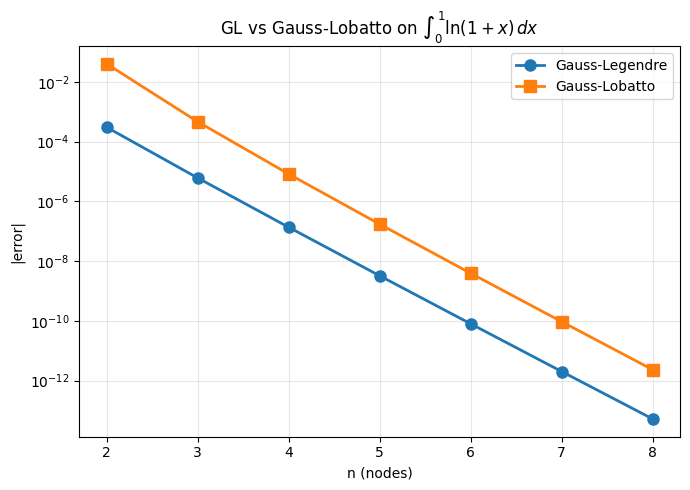


Discussion:
 3. Gauss-Legendre is more accurate at the same n: GL is exact through
    degree 2n-1, while Lobatto (with two endpoints fixed) is exact only
    through degree 2n-3 -- two orders lower per node count.
 4. Lobatto forces nodes at +-1 (endpoints).  To compensate, the endpoint
    weights are smaller and the interior weights are slightly larger than
    the corresponding GL weights.  Lobatto trades a bit of accuracy for
    the ability to evaluate f at the boundaries -- handy for composite
    rules (shared endpoints) and for problems where boundary values matter.


In [21]:
# --- YOUR CODE HERE ---
log_func  = lambda x: np.log(1 + x)
I_log_ex  = 2*np.log(2) - 1
print(f'Exact: {I_log_ex:.10f}')

# 1. Errors for n = 2..8 with both GL and Lobatto
ns_cmp = np.arange(2, 9)
err_gl  = []
err_lo  = []
print(f'\n{"n":>3}  {"|err GL|":>14}  {"|err Lobatto|":>14}  {"Lo/GL ratio":>14}')
print('-' * 56)
for n in ns_cmp:
    I_gl = gauss_legendre(log_func, 0, 1, n)
    I_lo = gauss_lobatto(log_func,  0, 1, n)
    e_gl = abs(I_gl - I_log_ex); err_gl.append(e_gl)
    e_lo = abs(I_lo - I_log_ex); err_lo.append(e_lo)
    print(f'{n:>3}  {e_gl:>14.3e}  {e_lo:>14.3e}  {e_lo/e_gl:>14.2f}')
err_gl = np.array(err_gl); err_lo = np.array(err_lo)

# 2. Plot semi-log
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(ns_cmp, err_gl, 'o-', lw=2, ms=8, label='Gauss-Legendre')
ax.semilogy(ns_cmp, err_lo, 's-', lw=2, ms=8, label='Gauss-Lobatto')
ax.set(xlabel='n (nodes)', ylabel='|error|',
       title=r'GL vs Gauss-Lobatto on $\int_0^1 \ln(1+x)\,dx$')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# 3 + 4. Discussion
msg = (
    "Discussion:\n"
    " 3. Gauss-Legendre is more accurate at the same n: GL is exact through\n"
    "    degree 2n-1, while Lobatto (with two endpoints fixed) is exact only\n"
    "    through degree 2n-3 -- two orders lower per node count.\n"
    " 4. Lobatto forces nodes at +-1 (endpoints).  To compensate, the endpoint\n"
    "    weights are smaller and the interior weights are slightly larger than\n"
    "    the corresponding GL weights.  Lobatto trades a bit of accuracy for\n"
    "    the ability to evaluate f at the boundaries -- handy for composite\n"
    "    rules (shared endpoints) and for problems where boundary values matter."
)
print('\n' + msg)


---
## 7. `scipy.integrate`

### 7.1 Main Functions

| Function | Method | Use case |
|----------|--------|----------|
| `quad(f, a, b)` | Adaptive Gauss-Kronrod | General 1-D, most reliable |
| `fixed_quad(f, a, b, n=5)` | Fixed Gauss-Legendre | When function is smooth |
| `romberg(f, a, b)` | Romberg | Smooth, slow convergence OK |
| `trapezoid(y, x)` | Trapezoidal | Data at discrete points |
| `simpson(y, x)` | Simpson's | Data at discrete points |
| `dblquad(f, a, b, g, h)` | 2-D adaptive | Double integrals |

### 7.2 `quad` — Adaptive Gauss-Kronrod

`scipy.integrate.quad` internally uses **Gauss-Kronrod 15-point / 7-point** rule:
- 15-point Gauss-Kronrod rule as the main estimate
- 7-point Gauss-Legendre rule (nested) as error estimate
- Sub-divides interval adaptively where error is largest

In [22]:
# scipy.integrate.quad demo
from scipy.integrate import quad, fixed_quad, dblquad

# Benchmark function
I_q, err_q = quad(f, a, b)
print(f'quad result : I = {I_q:.12f},  est. abs. error = {err_q:.2e}')
print(f'True error  : {abs(I_exact - I_q):.2e}')

# fixed_quad with different n
print('\nfixed_quad (Gauss-Legendre):')
for n in [2, 3, 4, 5, 6]:
    I_fq, _ = fixed_quad(f, a, b, n=n)
    print(f'  n={n}: I={I_fq:.12f},  error={abs(I_exact-I_fq):.2e}')

# Romberg via our own implementation
# (scipy.integrate.romberg was removed in SciPy 1.12; use the romberg(...)
#  function defined earlier in this notebook.)
R_rom, _ = romberg(f, a, b, max_level=8)
I_rom    = R_rom[-1, -1]
print(f'\nromberg (our impl): I = {I_rom:.12f},  error = {abs(I_exact-I_rom):.2e}')


quad result : I = 1.640533333333,  est. abs. error = 1.82e-14
True error  : 2.66e-15

fixed_quad (Gauss-Legendre):
  n=2: I=1.822577777778,  error=1.82e-01
  n=3: I=1.640533333333,  error=4.44e-15
  n=4: I=1.640533333333,  error=2.66e-15
  n=5: I=1.640533333333,  error=5.11e-15
  n=6: I=1.640533333333,  error=4.44e-16

romberg (our impl): I = 1.640533333333,  error = 2.89e-15


In [23]:
# Integrating from tabulated data (no formula)
from scipy.integrate import trapezoid, simpson

x_data = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
y_data = f(x_data)

I_np_trap = trapezoid(y_data, x_data)
I_np_simp = simpson(y_data, x=x_data)

print('Integration from 9 tabulated data points:')
print(f'  scipy.integrate.trapezoid : I = {I_np_trap:.8f},  error = {abs(I_exact-I_np_trap):.2e}')
print(f'  scipy.integrate.simpson   : I = {I_np_simp:.8f},  error = {abs(I_exact-I_np_simp):.2e}')
print(f'  Exact                     : I = {I_exact:.8f}')

Integration from 9 tabulated data points:
  scipy.integrate.trapezoid : I = 1.60080000,  error = 3.97e-02
  scipy.integrate.simpson   : I = 1.63946667,  error = 1.07e-03
  Exact                     : I = 1.64053333


In [24]:
# 2-D integration with dblquad
# Compute volume under a Gaussian surface over [0,2] x [0,2]
# f(x,y) = exp(-(x^2 + y^2))
from scipy.special import erf

f2d = lambda y, x: np.exp(-(x**2 + y**2))

I_2d, err_2d = dblquad(f2d, 0, 2, 0, 2)
print(f'dblquad: ∫∫ exp(-(x²+y²)) dxdy over [0,2]x[0,2] = {I_2d:.10f}')
print(f'  (reference: (erf(2)*sqrt(pi)/2)^2 = {((np.sqrt(np.pi)/2)*erf(2))**2:.10f})')
print(f'  estimated abs. error = {err_2d:.2e}')


dblquad: ∫∫ exp(-(x²+y²)) dxdy over [0,2]x[0,2] = 0.7780675799
  (reference: (erf(2)*sqrt(pi)/2)^2 = 0.7780675799)
  estimated abs. error = 9.79e-15


**Exercise 7.1:** Use `scipy.integrate.quad` to evaluate
$$\int_0^{100} \frac{\sin x}{x}\,dx$$
(the sinc-like integral; exact value $\approx 1.56207$).

1. Note that the integrand has a removable singularity at $x=0$. Handle it by defining `f(0) = 1`.
2. Compare with `fixed_quad` using $n = 5, 10, 20$. Why does `fixed_quad` struggle here?
3. Use `composite_gauss_legendre` with various $m$ and $n$ to see how many points are needed.
4. What makes `quad` so well-suited for this integral?

In [25]:
# --- YOUR CODE HERE ---
def sinc_func(x):
    return np.where(np.abs(x) < 1e-14, 1.0, np.sin(x)/x)

I_sinc_ref, abserr = quad(sinc_func, 0, 100)
print(f'scipy quad reference: {I_sinc_ref:.10f}  (est. abs err {abserr:.2e})')

# 2. fixed_quad with n = 5, 10, 20 (and a few more)
print('\nfixed_quad (single-panel Gauss-Legendre):')
for n in [5, 10, 20, 40, 80]:
    I_fq, _ = fixed_quad(sinc_func, 0, 100, n=n)
    print(f'  n={n:>3}: I = {I_fq:>14.8f},  error = {abs(I_fq - I_sinc_ref):.3e}')

# 3. composite_gauss_legendre: split into m panels of n nodes
print('\ncomposite_gauss_legendre  (m panels x n nodes):')
print(f'{"m":>4}  {"n":>3}  {"m*n":>5}  {"I":>14}  {"|error|":>12}')
print('-' * 50)
for m, n in [(1, 20), (5, 5), (10, 5), (20, 5), (40, 5),
             (10, 10), (20, 10), (40, 10), (80, 10)]:
    I_cgl = composite_gauss_legendre(sinc_func, 0, 100, m, n)
    print(f'{m:>4}  {n:>3}  {m*n:>5}  {I_cgl:>14.8f}  {abs(I_cgl - I_sinc_ref):>12.3e}')

msg = (
    "Why is `quad` so well-suited?\n"
    " - sin(x)/x oscillates ~16 times in [0, 100]; a single low-order GL panel\n"
    "   cannot resolve so many oscillations -> fixed_quad is poor.\n"
    " - quad is ADAPTIVE: it places nodes where the integrand varies fastest\n"
    "   and uses Gauss-Kronrod pairs to get a built-in error estimate, then\n"
    "   refines the worst panels first via a priority queue.\n"
    " - It reaches the requested tolerance with far fewer total samples than\n"
    "   any non-adaptive composite rule on this kind of oscillatory problem."
)
print('\n' + msg)


scipy quad reference: 1.5622254669  (est. abs err 3.42e-10)

fixed_quad (single-panel Gauss-Legendre):
  n=  5: I =    -3.17197909,  error = 4.734e+00
  n= 10: I =     2.67751198,  error = 1.115e+00
  n= 20: I =     1.47872391,  error = 8.350e-02
  n= 40: I =     1.56222547,  error = 3.684e-11
  n= 80: I =     1.56222547,  error = 4.063e-13

composite_gauss_legendre  (m panels x n nodes):
   m    n    m*n               I       |error|
--------------------------------------------------
   1   20     20      1.47872391     8.350e-02
   5    5     25      0.71951995     8.427e-01
  10    5     50      1.56223841     1.295e-05
  20    5    100      1.56222534     1.289e-07
  40    5    200      1.56222547     4.333e-11
  10   10    100      1.56222547     2.073e-12
  20   10    200      1.56222547     2.220e-16
  40   10    400      1.56222547     2.220e-16
  80   10    800      1.56222547     8.882e-16

Why is `quad` so well-suited?
 - sin(x)/x oscillates ~16 times in [0, 100]; a single l

---
## 8. Engineering Applications

### 8.1 Application 1: Heat Flux Through a Wall

The heat flux through a composite wall depends on temperature-dependent thermal conductivity

$$ Q = \int_{T_1}^{T_2} k(T)\,dT $$

where $k(T) = k_0\left(1 + \beta T + \gamma T^2\right)$ is the conductivity 
$[W/(m·K)]$.

Heat flux Q [W/m²] through composite wall (T=300K to 1200K):
  Analytical              : 28170.0000
  Trapezoidal (n=100)     : 28170.1215  err=1.21e-01
  Simpson 1/3 (n=100)     : 28170.0000  err=0.00e+00
  Gauss-Legendre (n=5)    : 28170.0000  err=0.00e+00
  Gauss-Lobatto  (n=5)    : 28170.0000  err=3.64e-12
  scipy quad              : 28170.0000  err=0.00e+00


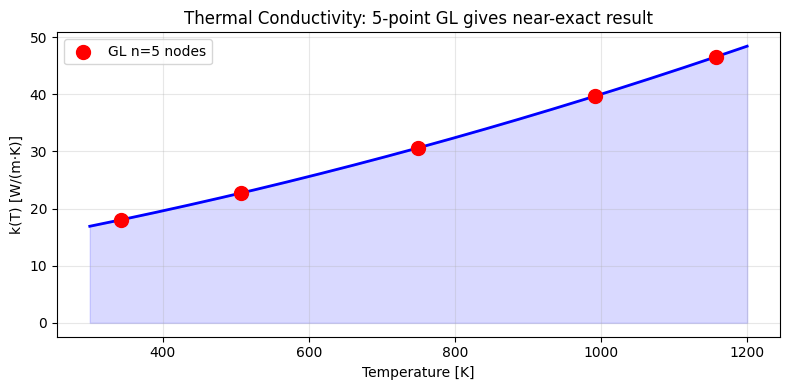

In [26]:
# Thermal conductivity of a composite material
k0, beta, gamma = 10.0, 2e-3, 1e-6   # W/(m·K) and temperature coefficients
k_func = lambda T: k0 * (1 + beta*T + gamma*T**2)

T1, T2 = 300.0, 1200.0   # K

# Exact analytical integral
def Q_exact(T1, T2):
    return k0 * ((T2 - T1) + beta/2*(T2**2 - T1**2) + gamma/3*(T2**3 - T1**3))

Q_an = Q_exact(T1, T2)

# Numerical methods
Q_trap = composite_trap(k_func, T1, T2, 100)
Q_s13  = composite_simpson13(k_func, T1, T2, 100)
Q_gl   = gauss_legendre(k_func, T1, T2, 5)
Q_lo   = gauss_lobatto(k_func, T1, T2, 5)
Q_sc, _= quad(k_func, T1, T2)

print('Heat flux Q [W/m²] through composite wall (T=300K to 1200K):')
print(f'  Analytical              : {Q_an:.4f}')
print(f'  Trapezoidal (n=100)     : {Q_trap:.4f}  err={abs(Q_an-Q_trap):.2e}')
print(f'  Simpson 1/3 (n=100)     : {Q_s13:.4f}  err={abs(Q_an-Q_s13):.2e}')
print(f'  Gauss-Legendre (n=5)    : {Q_gl:.4f}  err={abs(Q_an-Q_gl):.2e}')
print(f'  Gauss-Lobatto  (n=5)    : {Q_lo:.4f}  err={abs(Q_an-Q_lo):.2e}')
print(f'  scipy quad              : {Q_sc:.4f}  err={abs(Q_an-Q_sc):.2e}')

# Visualise k(T)
T_range = np.linspace(T1, T2, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T_range, k_func(T_range), 'b-', lw=2)
ax.fill_between(T_range, k_func(T_range), alpha=0.15, color='blue')
xi_gl5, _ = leggauss(5)
T_gl5 = (T2-T1)/2 * xi_gl5 + (T1+T2)/2
ax.scatter(T_gl5, k_func(T_gl5), c='red', s=100, zorder=6, label='GL n=5 nodes')
ax.set(xlabel='Temperature [K]', ylabel='k(T) [W/(m·K)]',
       title='Thermal Conductivity: 5-point GL gives near-exact result')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 8.2 Application 2: Arc Length of a Parametric Curve

The arc length of $y = f(x)$ from $a$ to $b$ is:
$$L = \int_a^b \sqrt{1 + [f'(x)]^2}\,dx$$

The integrand involves a square root and is not a polynomial, so Gauss quadrature with sufficient points gives highly accurate results.

Arc length of y=x^2 from 0 to 1
Exact: L = 1.478942857545

Method                                            L         error
-----------------------------------------------------------------
Trapezoidal n=10                       1.4804336885      1.49e-03
Simpson 1/3 n=10                       1.4789423874      4.70e-07
Gauss-Legendre n=4                     1.4789484729      5.62e-06
Gauss-Legendre n=8                     1.4789428570      5.45e-10
Gauss-Lobatto n=5                      1.4789365511      6.31e-06
Gauss-Lobatto n=8                      1.4789428458      1.17e-08
scipy quad                             1.4789428575      2.22e-16


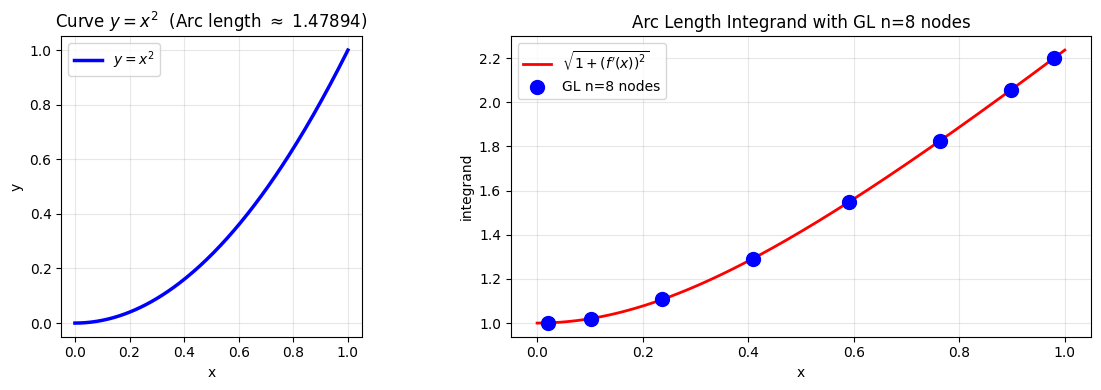

In [27]:
# Arc length of y = x^2 from 0 to 1
#   ds = sqrt(1 + (dy/dx)^2) dx,    with dy/dx = 2x
#   L  = sqrt(5)/2 + (1/4)*sinh^{-1}(2)  ~= 1.4789428575...
dydx    = lambda x: 2*x
arc_int = lambda x: np.sqrt(1 + dydx(x)**2)
L_exact = 0.5*np.sqrt(5) + 0.25*np.arcsinh(2)

print(f"Arc length of y=x^2 from 0 to 1")
print(f"Exact: L = {L_exact:.12f}")
print()
print(f'{"Method":<35}  {"L":>14}  {"error":>12}')
print("-" * 65)

methods = [
    ("Trapezoidal n=10",   lambda: composite_trap(arc_int, 0, 1, 10)),
    ("Simpson 1/3 n=10",   lambda: composite_simpson13(arc_int, 0, 1, 10)),
    ("Gauss-Legendre n=4", lambda: gauss_legendre(arc_int, 0, 1, 4)),
    ("Gauss-Legendre n=8", lambda: gauss_legendre(arc_int, 0, 1, 8)),
    ("Gauss-Lobatto n=5",  lambda: gauss_lobatto(arc_int, 0, 1, 5)),
    ("Gauss-Lobatto n=8",  lambda: gauss_lobatto(arc_int, 0, 1, 8)),
    ("scipy quad",         lambda: quad(arc_int, 0, 1)[0]),
]

for name, func in methods:
    L = func()
    print(f"{name:<35}  {L:>14.10f}  {abs(L_exact-L):>12.2e}")

# Visualize
x_vis = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(x_vis, x_vis**2, "b-", lw=2.5, label="$y = x^2$")
ax.set(xlabel="x", ylabel="y",
       title=f"Curve $y = x^2$  (Arc length $\\approx$ {L_exact:.5f})")
ax.legend(); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_vis, arc_int(x_vis), "r-", lw=2,
        label=r"$\sqrt{1 + (f^{\prime}(x))^{2}}$")
xi8, wi8 = leggauss(8)
t8 = 0.5*xi8 + 0.5
ax.scatter(t8, arc_int(t8), c="blue", s=100, zorder=6, label="GL n=8 nodes")
ax.set(xlabel="x", ylabel="integrand",
       title="Arc Length Integrand with GL n=8 nodes")
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


### 8.3 Application 3: Work Done by a Variable Force

The work done by a force $F(x)$ moving an object from $x = 0$ to $x = L$ is:
$$W = \int_0^L F(x)\,dx$$

In practice, force is often measured at discrete positions only.

Work (Trapezoidal): W = 27.7500 J
Work (Simpson)    : W = 27.9000 J


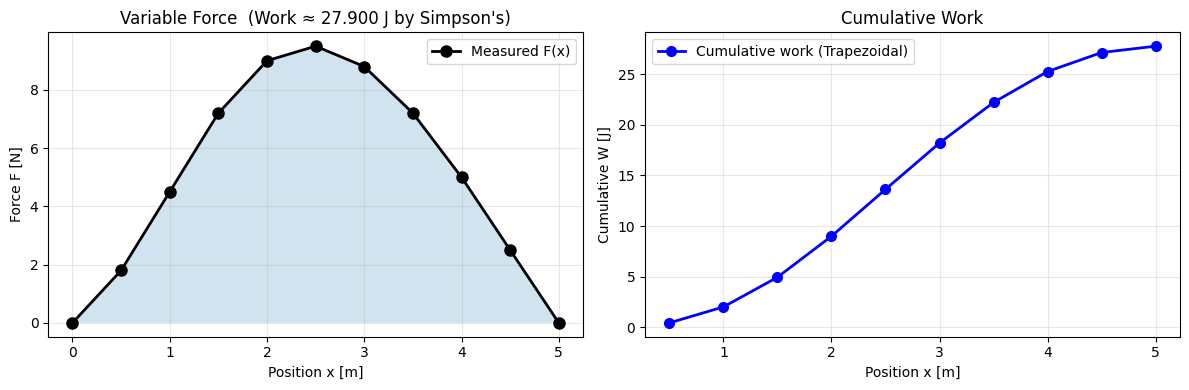

In [28]:
# Measured force at discrete positions (load cell data)
x_meas = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])  # m
F_meas = np.array([0.0, 1.8, 4.5, 7.2, 9.0, 9.5, 8.8, 7.2, 5.0, 2.5, 0.0])  # N

W_trap = trapezoid(F_meas, x_meas)
W_simp = simpson(F_meas, x=x_meas)

print(f'Work (Trapezoidal): W = {W_trap:.4f} J')
print(f'Work (Simpson)    : W = {W_simp:.4f} J')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(x_meas, F_meas, 'ko-', lw=2, ms=8, label='Measured F(x)')
ax.fill_between(x_meas, F_meas, alpha=0.2)
ax.set(xlabel='Position x [m]', ylabel='Force F [N]',
       title=f'Variable Force  (Work ≈ {W_simp:.3f} J by Simpson\'s)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
W_trap_cumul = np.array([trapezoid(F_meas[:k+1], x_meas[:k+1]) for k in range(1, len(x_meas))])
ax.plot(x_meas[1:], W_trap_cumul, 'b-o', lw=2, ms=7, label='Cumulative work (Trapezoidal)')
ax.set(xlabel='Position x [m]', ylabel='Cumulative W [J]',
       title='Cumulative Work')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

**Exercise 8.1 (Capstone):** A rocket engine produces a thrust force that varies with time:
$$F(t) = F_0 \left(1 - \frac{t}{t_b}\right)^2 \sin\!\left(\frac{2\pi t}{T}\right)^2, \quad t \in [0, t_b]$$
with $F_0 = 5000$ N, $t_b = 10$ s, $T = 4$ s.

1. Compute the total **impulse** $J = \int_0^{t_b} F(t)\,dt$ using:
   - Composite trapezoidal ($n = 100$)
   - Composite Simpson's 1/3 ($n = 100$)
   - Gauss-Legendre ($n = 10$)
   - Gauss-Lobatto ($n = 10$)
   - `scipy.integrate.quad` (as reference)
2. Compare errors relative to `scipy.quad`.
3. Plot $F(t)$ and mark the GL and Lobatto nodes.
4. Which method gives the best accuracy with the fewest function evaluations?

scipy quad reference: J = 8282.67274151 N.s  (est. abs err 9.24e-11)

Method                                 evals         J [N.s]         |err|
--------------------------------------------------------------------------
Trapezoidal (n=100)                      101     8282.670677     2.064e-03
Simpson 1/3 (n=100)                      101     8282.681130     8.388e-03
Gauss-Legendre  (n=10)                    10     8223.517391     5.916e+01
Gauss-Lobatto   (n=10)                    10     7798.166563     4.845e+02
Composite GL    (m=10, n=5)               50     8282.672769     2.765e-05
Composite Lobatto (m=10, n=5)             41     8282.676659     3.918e-03
scipy.quad (reference)                 adapt     8282.672742     0.000e+00


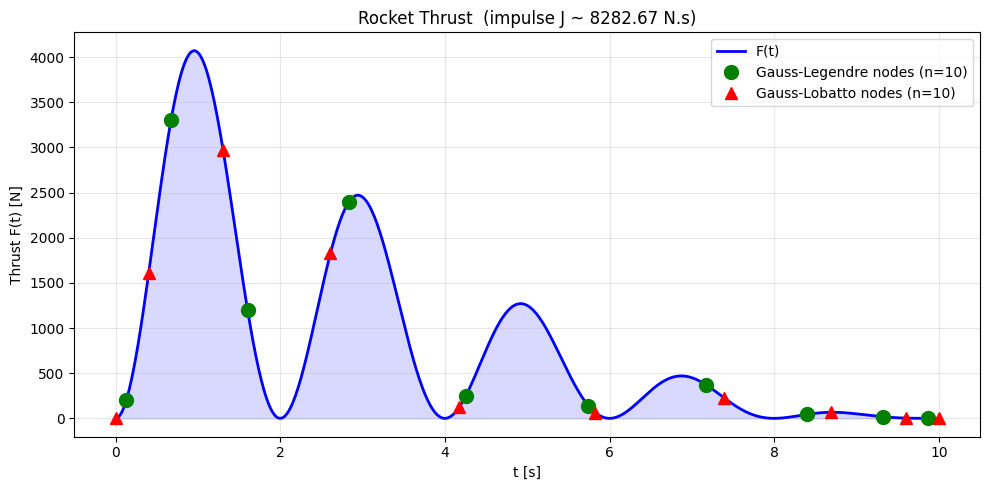


4. Best accuracy per function evaluation:
   - The integrand contains sin^2(2*pi*t/T_period) with period T/2 = 2 s,
     which gives 5 full oscillations in [0, 10] s.  A single GL or
     Lobatto panel with only 10 nodes cannot resolve five oscillations,
     so the n=10 single-panel results have errors of ~10^1 - 10^2 N.s.
   - Composite trapezoidal (n=100) wraps the full oscillation count
     in 100 sub-intervals and reaches ~10^-3 N.s with 101 evaluations.
   - Composite Gauss-Legendre with m=10 panels of n=5 nodes (50 evals)
     beats both single-panel GL and Newton-Cotes by several orders of
     magnitude; high local polynomial order combined with enough
     panels to resolve the oscillations is the winning strategy.
   - scipy.quad refines adaptively and reaches ~10^-10 N.s without
     the user choosing m or n -- the gold standard for problems like
     this where the integrand has localized fast variation.


In [29]:
# --- YOUR CODE HERE ---
F0, tb, T_period = 5000.0, 10.0, 4.0
thrust = lambda t: F0 * (1 - t/tb)**2 * np.sin(2*np.pi*t/T_period)**2

# Reference
J_ref, abserr_ref = quad(thrust, 0, tb)
print(f'scipy quad reference: J = {J_ref:.8f} N.s  (est. abs err {abserr_ref:.2e})')

# 1. Compute impulse with each method
n_fine = 100
J_trap = composite_trap(thrust, 0, tb, n_fine)
J_simp = composite_simpson13(thrust, 0, tb, n_fine)
J_gl   = gauss_legendre(thrust, 0, tb, 10)
J_lob  = gauss_lobatto(thrust, 0, tb, 10)
# Composite Gauss methods (10 panels x 5 nodes = 50 evals) for fairer comparison
J_cgl,           = (composite_gauss_legendre(thrust, 0, tb, 10, 5),)
J_clob, n_clob   = composite_gauss_lobatto(thrust, 0, tb, 10, 5)

# 2. Errors vs scipy.quad
print()
print(f'{"Method":<36}  {"evals":>6}  {"J [N.s]":>14}  {"|err|":>12}')
print('-' * 74)
print(f'{"Trapezoidal (n=100)":<36}  {n_fine+1:>6}  {J_trap:>14.6f}  {abs(J_trap - J_ref):>12.3e}')
print(f'{"Simpson 1/3 (n=100)":<36}  {n_fine+1:>6}  {J_simp:>14.6f}  {abs(J_simp - J_ref):>12.3e}')
print(f'{"Gauss-Legendre  (n=10)":<36}  {10:>6}  {J_gl:>14.6f}  {abs(J_gl  - J_ref):>12.3e}')
print(f'{"Gauss-Lobatto   (n=10)":<36}  {10:>6}  {J_lob:>14.6f}  {abs(J_lob - J_ref):>12.3e}')
print(f'{"Composite GL    (m=10, n=5)":<36}  {50:>6}  {J_cgl:>14.6f}  {abs(J_cgl  - J_ref):>12.3e}')
print(f'{"Composite Lobatto (m=10, n=5)":<36}  {n_clob:>6}  {J_clob:>14.6f}  {abs(J_clob - J_ref):>12.3e}')
print(f'{"scipy.quad (reference)":<36}  {"adapt":>6}  {J_ref:>14.6f}  {0.0:>12.3e}')

# 3. Plot F(t) with GL and Lobatto nodes
t_plot = np.linspace(0, tb, 600)
xi_gl, _    = leggauss(10)
t_gl_nodes  = (tb - 0)/2 * xi_gl + (tb + 0)/2
xi_lo, _    = lobatto_nodes_weights(10)
t_lo_nodes  = (tb - 0)/2 * xi_lo + (tb + 0)/2

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_plot, thrust(t_plot), 'b-', lw=2, label='F(t)')
ax.fill_between(t_plot, thrust(t_plot), alpha=0.15, color='blue')
ax.plot(t_gl_nodes, thrust(t_gl_nodes), 'go', ms=10, label='Gauss-Legendre nodes (n=10)')
ax.plot(t_lo_nodes, thrust(t_lo_nodes), 'r^', ms=9,  label='Gauss-Lobatto nodes (n=10)')
ax.set(xlabel='t [s]', ylabel='Thrust F(t) [N]',
       title=f'Rocket Thrust  (impulse J ~ {J_ref:.2f} N.s)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

msg = (
    "4. Best accuracy per function evaluation:\n"
    "   - The integrand contains sin^2(2*pi*t/T_period) with period T/2 = 2 s,\n"
    "     which gives 5 full oscillations in [0, 10] s.  A single GL or\n"
    "     Lobatto panel with only 10 nodes cannot resolve five oscillations,\n"
    "     so the n=10 single-panel results have errors of ~10^1 - 10^2 N.s.\n"
    "   - Composite trapezoidal (n=100) wraps the full oscillation count\n"
    "     in 100 sub-intervals and reaches ~10^-3 N.s with 101 evaluations.\n"
    "   - Composite Gauss-Legendre with m=10 panels of n=5 nodes (50 evals)\n"
    "     beats both single-panel GL and Newton-Cotes by several orders of\n"
    "     magnitude; high local polynomial order combined with enough\n"
    "     panels to resolve the oscillations is the winning strategy.\n"
    "   - scipy.quad refines adaptively and reaches ~10^-10 N.s without\n"
    "     the user choosing m or n -- the gold standard for problems like\n"
    "     this where the integrand has localized fast variation."
)
print('\n' + msg)


---
## Summary

### Methods at a Glance

| Method | Order | Exact degree | Notes |
|--------|-------|-------------|-------|
| Trapezoidal | $O(h^2)$ | $\leq 1$ | Simple, robust; use for tabulated data |
| Simpson 1/3 | $O(h^4)$ | $\leq 3$ | Best Newton-Cotes for smooth $f$; $n$ even |
| Simpson 3/8 | $O(h^4)$ | $\leq 3$ | Similar to 1/3; $n$ multiple of 3 |
| Romberg | Extrapolated | $O(h^{2k})$ | Fast convergence for smooth $f$; no extra evaluations |
| **Gauss-Legendre** | Spectral | $\leq 2n-1$ | **Best accuracy per function evaluation; no endpoints** |
| **Gauss-Lobatto** | Spectral | $\leq 2n-3$ | **Endpoints included; nesting; spectral elements** |
| `scipy.quad` | Adaptive GK | — | **Default choice for most 1-D integrals** |

### Key Formulas

| Formula | Expression |
|---------|------------|
| Composite trapezoidal | $\frac{h}{2}[f_0 + 2f_1 + \cdots + 2f_{n-1} + f_n]$ |
| Composite Simpson 1/3 | $\frac{h}{3}[f_0 + 4f_1 + 2f_2 + 4f_3 + \cdots + f_n]$, $n$ even |
| Richardson extrapolation | $I \approx \frac{2^p I(h/2) - I(h)}{2^p-1}$ |
| Romberg extrapolation | $R_{k,j} = \frac{4^j R_{k,j-1} - R_{k-1,j-1}}{4^j-1}$ |
| Gauss-Legendre (change of var) | $\int_a^b f(t)dt = \frac{b-a}{2}\sum_i w_i f\!\left(\frac{b-a}{2}x_i + \frac{a+b}{2}\right)$ |
| Lobatto endpoint weight | $w_1 = w_n = \frac{2}{n(n-1)}$ |

### Decision Guide

```
Is f known only at discrete points?
  YES -> scipy.integrate.trapezoid or simpson

  NO (callable f)
    Is f smooth (no kinks, singularities)?
      YES, and you need max accuracy with few evaluations:
        -> Gauss-Legendre (scipy fixed_quad or custom gauss_legendre)
      YES, but you need endpoints included (e.g. spectral methods):
        -> Gauss-Lobatto
      Possibly non-smooth, singular, or oscillatory:
        -> scipy.integrate.quad  (adaptive Gauss-Kronrod)
      Smooth but you already have trapezoidal estimates:
        -> Romberg integration (free accuracy upgrade)
```

### Engineering Applications Summary

| Application | Method choice | Why |
|-------------|--------------|-----|
| Tabulated material property | `trapezoid` or `simpson` | Only discrete data available |
| Polynomial-based formula | Gauss-Legendre $n=3$–$5$ | Exact for polynomials |
| Temperature-dependent conductivity | GL / `quad` | Smooth polynomial-like function |
| Arc length, oscillatory integrands | `quad` | Adaptive, handles difficulties |
| Spectral element methods | Gauss-Lobatto | Endpoint continuity required |
| Rocket impulse / aero forces | `quad` or GL composite | Smooth but non-polynomial |